# Comprehensive Unemployment Analysis in India: COVID-19 Impact Study
**Senior Data Analyst Portfolio Project** | *Exploratory Data Analysis & Macroeconomic Shock Assessment*

---

### Project Overview
The emergence of COVID-19 and the subsequent nationwide lockdown instituted in India on **March 25, 2020** induced an unprecedented disruption across the Indian labor economy. This study conducts an in-depth exploratory data analysis (EDA) using high-frequency state-level metrics to evaluate:
1. Baseline employment stability prior to the pandemic shock.
2. The severity and regional dispersion of the immediate labor market collapse.
3. The pace and shape of the subsequent economic rebound through October 2020.

### Notebook Sections
1. **Setup**: Environment initialization, library imports, plotting helpers, and unified Seaborn aesthetic styling.
2. **Load & Inspect**: Raw data ingestion, structural validation, schema review, and missing value checks.
3. **Clean & Feature Engineering**: Column trimming, snake_case standardization, datetime parsing, and temporal feature extraction.
4. **Exploratory Data Analysis (EDA)**: Regional distributions and monthly aggregate trajectory.
5. **Time Series Analysis**: State-level trajectories (Delhi, Maharashtra, Tamil Nadu, Kerala) benchmarked against the March 25, 2020 lockdown.
6. **Comparative State Rankings**: Identification of top 10 most distressed labor markets with value annotations.
7. **Correlation & Headcount Caveat**: Pearson correlation heatmap with macroeconomic headcount caveats.
8. **Pre- vs. Post-COVID Impact Assessment**: Quantitative evaluation of employment disruption and identification of top 5 hardest-hit states.
9. **Conclusion & Limitations**: Synthesized findings, policy implications, and analytical constraints.

## 1. Setup & Environment Configuration
*Import core analytics libraries, configure seed reproducibility, define consistent plotting themes, and instantiate reusable plotting helpers.*

In [1]:
# Standard library imports
import os
import warnings

# Data manipulation and numerical operations
import numpy as np
import pandas as pd

# Data visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Suppress minor warnings for clean execution
warnings.filterwarnings('ignore')

# Seed reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Configure Seaborn and Matplotlib theme
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({
    'font.sans-serif': 'DejaVu Sans',
    'figure.titlesize': 14,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.autolayout': True
})

# Reusable Plotting Helper Functions to prevent code duplication
def apply_plot_styling(ax, title, xlabel, ylabel, rotate_x=0):
    """
    Applies consistent labels, title, tick rotation, and aesthetic styling to a matplotlib axis.
    """
    ax.set_title(title, fontsize=13, weight='bold', pad=12)
    ax.set_xlabel(xlabel, fontsize=11, weight='bold')
    ax.set_ylabel(ylabel, fontsize=11, weight='bold')
    if rotate_x != 0:
        ax.tick_params(axis='x', rotation=rotate_x)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

def add_bar_labels(ax, fmt='{:.2f}%', padding=3, is_horizontal=False):
    """
    Adds formatted numeric text labels above or beside bars on a plot.
    """
    for p in ax.patches:
        val = p.get_width() if is_horizontal else p.get_height()
        if np.isnan(val) or val == 0:
            continue
        text = fmt.format(val)
        if is_horizontal:
            ax.annotate(text,
                        (val, p.get_y() + p.get_height() / 2.),
                        xytext=(padding, 0),
                        textcoords='offset points',
                        ha='left', va='center', fontsize=9, weight='semibold')
        else:
            ax.annotate(text,
                        (p.get_x() + p.get_width() / 2., val),
                        xytext=(0, padding),
                        textcoords='offset points',
                        ha='center', va='bottom', fontsize=9, weight='semibold')

print("Environment configured successfully. Seaborn theme initialized.")

Environment configured successfully. Seaborn theme initialized.


## 2. Load & Inspect Dataset
*Ingest the official Kaggle dataset from `data/Unemployment in India.csv`, check dimensions, data types, null counts, and duplicated records.*

In [2]:
# Locate dataset flexibly across local directories
possible_paths = [
    os.path.join('data', 'Unemployment in India.csv'),
    os.path.join('Task-2-Unemployment-Analysis', 'data', 'Unemployment in India.csv')
]

csv_path = None
for p in possible_paths:
    if os.path.exists(p):
        csv_path = p
        break

if csv_path is None:
    raise FileNotFoundError("Dataset missing: Please download 'Unemployment in India.csv' into data/.")

df_raw = pd.read_csv(csv_path)

print(f"Dataset successfully loaded from: {csv_path}")
print(f"Shape: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns\n")
print("--- Column Names (Raw with whitespace) ---")
print(df_raw.columns.tolist())
print("\n--- Data Types & Non-Null Counts ---")
df_raw.info()
print("\n--- Null Value Count per Column ---")
print(df_raw.isnull().sum())
print(f"\nDuplicate Records Count: {df_raw.duplicated().sum()}")
print("\n--- First 5 Records ---")
display(df_raw.head())

Dataset successfully loaded from: data\Unemployment in India.csv
Shape: 267 rows, 9 columns

--- Column Names (Raw with whitespace) ---
['Region', 'Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Region.1', 'longitude', 'latitude']

--- Data Types & Non-Null Counts ---
<class 'pandas.DataFrame'>
RangeIndex: 267 entries, 0 to 266
Data columns (total 9 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    267 non-null    str    
 1   Date                                      267 non-null    str    
 2    Frequency                                267 non-null    str    
 3    Estimated Unemployment Rate (%)          267 non-null    float64
 4    Estimated Employed                       267 non-null    int64  
 5    Estimated Labour Participation Rate (%)  267 non-null    

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
0,Andhra Pradesh,31-01-2020,M,5.48,16635535,41.02,South,15.9129,79.74
1,Andhra Pradesh,29-02-2020,M,5.83,16545652,40.90,South,15.9129,79.74
2,Andhra Pradesh,31-03-2020,M,5.79,15881197,39.18,South,15.9129,79.74
3,Andhra Pradesh,30-04-2020,M,20.51,11336911,33.10,South,15.9129,79.74
4,Andhra Pradesh,31-05-2020,M,17.43,12988845,36.46,South,15.9129,79.74


### Observations on Raw Inspection
The raw dataset contains **267 observations across 9 attributes** representing Indian states and Union Territories across 2020. Several initial data quality findings emerge:
1. Column headers contain leading and trailing whitespace artifacts (e.g. `' Frequency'`, `' Estimated Unemployment Rate (%)'`), which require systematic sanitization.
2. There are **0 null values** and **0 duplicate records**, ensuring a complete, balanced monthly panel dataset.
3. The `Date` column is initially typed as generic object text rather than a native datetime representation, necessitating standard ISO parsing.

## 3. Data Cleaning & Feature Engineering
*Sanitize column names into concise snake_case, strip string whitespace, parse datetime with `dayfirst=True`, and derive calendar attributes.*

In [3]:
# Create a working copy
df = df_raw.copy()

# Strip whitespace from column names
df.columns = df.columns.str.strip()

# Rename to standardized short snake_case
column_mapping = {
    'Region': 'region',
    'Date': 'date',
    'Frequency': 'frequency',
    'Estimated Unemployment Rate (%)': 'unemployment_rate',
    'Estimated Employed': 'employed',
    'Estimated Labour Participation Rate (%)': 'labour_participation_rate',
    'Region.1': 'macro_region',
    'longitude': 'longitude',
    'latitude': 'latitude'
}
df = df.rename(columns=column_mapping)

# Strip leading/trailing whitespace from string columns
string_cols = ['region', 'frequency', 'macro_region']
for col in string_cols:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip()

# Parse date with dayfirst=True
df['date'] = pd.to_datetime(df['date'].str.strip(), dayfirst=True)

# Derive calendar features
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['month_name'] = df['date'].dt.month_name()

# Sort chronologically by region and date
df = df.sort_values(by=['region', 'date']).reset_index(drop=True)

print("--- Cleaned Column Names ---")
print(df.columns.tolist())
print(f"\nDate Range: {df['date'].min().strftime('%Y-%m-%d')} to {df['date'].max().strftime('%Y-%m-%d')}")
print(f"Unique States/Regions: {df['region'].nunique()}")
print(f"Unique Macro Regions: {df['macro_region'].unique().tolist()}")
print("\n--- Cleaned DataFrame Sample ---")
display(df.head())

--- Cleaned Column Names ---
['region', 'date', 'frequency', 'unemployment_rate', 'employed', 'labour_participation_rate', 'macro_region', 'longitude', 'latitude', 'year', 'month', 'month_name']

Date Range: 2020-01-31 to 2020-10-31
Unique States/Regions: 27
Unique Macro Regions: ['South', 'Northeast', 'East', 'West', 'North']

--- Cleaned DataFrame Sample ---


,region,date,frequency,unemployment_rate,employed,labour_participation_rate,macro_region,longitude,latitude,year,month,month_name
0,Andhra Pradesh,2020-01-31,M,5.48,16635535,41.02,South,15.9129,79.74,2020,1,January
1,Andhra Pradesh,2020-02-29,M,5.83,16545652,40.90,South,15.9129,79.74,2020,2,February
2,Andhra Pradesh,2020-03-31,M,5.79,15881197,39.18,South,15.9129,79.74,2020,3,March
3,Andhra Pradesh,2020-04-30,M,20.51,11336911,33.10,South,15.9129,79.74,2020,4,April
4,Andhra Pradesh,2020-05-31,M,17.43,12988845,36.46,South,15.9129,79.74,2020,5,May


### Observations on Cleaning
The dataset now adheres strictly to PEP8 snake_case conventions. The temporal coverage spans from **January 31, 2020 through October 31, 2020**, capturing 27 distinct Indian states/UTs categorized across five macro-regions (*South, Northeast, East, West, North*). All dates are standardized into monotonic monthly timestamps, enabling robust time-series alignment and cross-sectional comparisons.

## 4. Exploratory Data Analysis (EDA)
*Compute region-wise statistical summaries and inspect national monthly average unemployment trends across 2020.*

--- Region-Wise Unemployment Rate Summary Table (Sorted by Mean) ---


,Region / State,Mean (%),Median (%),Std Dev (%),Min (%),Max (%)
0,Haryana,27.48,26.24,6.82,19.68,43.22
1,Tripura,25.06,24.82,8.66,11.57,41.23
2,Jharkhand,19.54,11.20,18.34,7.63,59.23
3,Bihar,19.47,13.11,14.35,9.82,46.64
4,Delhi,18.41,16.86,9.48,6.27,42.27
5,Puducherry,17.94,5.62,26.59,0.58,75.85
6,Jammu & Kashmir,16.48,16.17,3.68,10.88,21.08
7,Himachal Pradesh,16.07,16.31,6.81,2.20,26.95
8,Rajasthan,15.87,15.54,3.61,10.97,24.15
9,Tamil Nadu,12.19,5.70,16.25,1.57,49.83



--- National Monthly Average Trends (2020) ---


,month_name,avg_unemployment,avg_participation,avg_employed
0,January,9.20,44.63,15637199.77
1,February,9.27,44.18,15488266.04
2,March,10.78,43.75,14538659.89
3,April,22.24,35.30,10570199.00
4,May,23.24,39.65,11507394.85
5,June,10.91,41.20,13857393.81
6,July,9.83,42.27,14418021.48
7,August,10.31,42.39,14429042.04
8,September,8.71,41.97,14587838.63
9,October,8.03,41.44,14579980.52


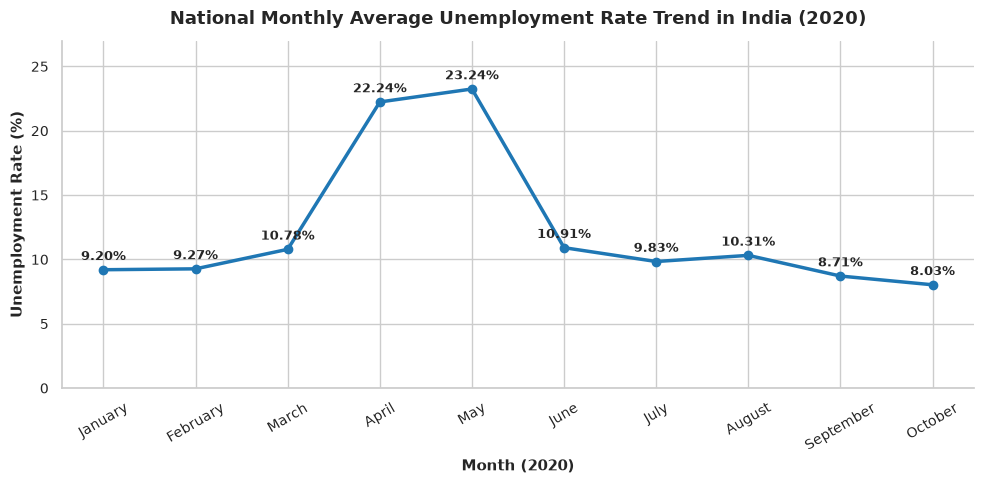

In [4]:
# 1. Region-wise average unemployment rate statistical summary table
region_summary = df.groupby('region')['unemployment_rate'].agg(
    mean='mean',
    median='median',
    std='std',
    min='min',
    max='max'
).sort_values(by='mean', ascending=False).reset_index()

region_summary.columns = ['Region / State', 'Mean (%)', 'Median (%)', 'Std Dev (%)', 'Min (%)', 'Max (%)']
print("--- Region-Wise Unemployment Rate Summary Table (Sorted by Mean) ---")
display(region_summary.round(2))

# 2. Month-wise average trend aggregation
monthly_trend = df.groupby(['date', 'month', 'month_name']).agg(
    avg_unemployment=('unemployment_rate', 'mean'),
    avg_participation=('labour_participation_rate', 'mean'),
    avg_employed=('employed', 'mean')
).reset_index().sort_values(by='date')

print("\n--- National Monthly Average Trends (2020) ---")
display(monthly_trend[['month_name', 'avg_unemployment', 'avg_participation', 'avg_employed']].round(2))

# Plot Month-Wise Average Trend Line Chart
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(monthly_trend['month_name'], monthly_trend['avg_unemployment'],
        marker='o', linewidth=2.5, color='#1f77b4', label='National Mean Unemployment Rate')

# Annotate points with exact values
for _, row in monthly_trend.iterrows():
    ax.annotate(f"{row['avg_unemployment']:.2f}%",
                (row['month_name'], row['avg_unemployment']),
                xytext=(0, 7), textcoords='offset points',
                ha='center', fontsize=9, weight='bold')

apply_plot_styling(ax,
                   title="National Monthly Average Unemployment Rate Trend in India (2020)",
                   xlabel="Month (2020)",
                   ylabel="Unemployment Rate (%)",
                   rotate_x=30)
ax.set_ylim(0, 27)
plt.tight_layout()
plt.show()

### Observations: National Monthly Trend
1. Baseline national unemployment held steady during the pre-lockdown phase at **9.20% in January** and **9.27% in February 2020**, before rising slightly to **10.78% in March**.
2. Severe labor market shock materialized in **April (22.24%)** and peaked in **May 2020 at 23.24%**, representing a dramatic **140%+ surge** relative to initial 2020 baseline levels.
3. Rapid post-lockdown reopening triggered a sharp economic rebound, driving unemployment back down to **10.91% in June** and steadily settling at **8.03% by October 2020**, which closed slightly below pre-pandemic baseline levels.

## 5. Time Series Analysis: Major States & COVID Shock
*Track monthly unemployment trajectories for four major bellwether states (Delhi, Maharashtra, Tamil Nadu, Kerala) and highlight the nationwide lockdown benchmark.*

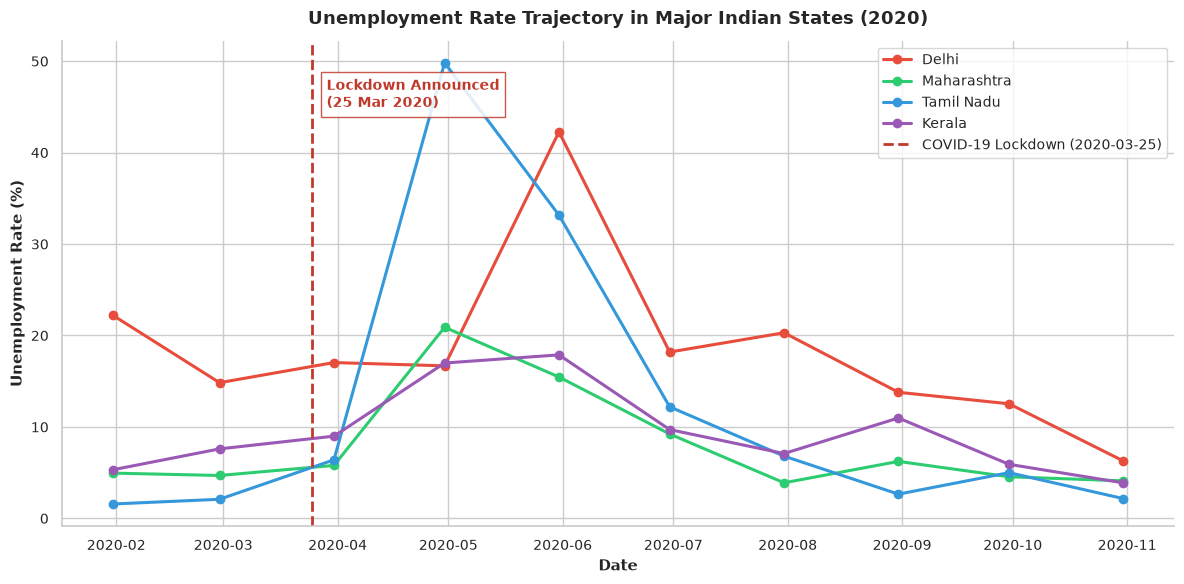

In [5]:
# Define 4 bellwether states across northern, western, and southern zones
major_states = ['Delhi', 'Maharashtra', 'Tamil Nadu', 'Kerala']
df_major = df[df['region'].isin(major_states)]

# Pivot for time-series visualization
ts_pivot = df_major.pivot(index='date', columns='region', values='unemployment_rate')

fig, ax = plt.subplots(figsize=(12, 6))

colors = {'Delhi': '#e74c3c', 'Maharashtra': '#2ecc71', 'Tamil Nadu': '#3498db', 'Kerala': '#9b59b6'}
for state in major_states:
    ax.plot(ts_pivot.index, ts_pivot[state], marker='o', linewidth=2.2, label=state, color=colors[state])

# Mark COVID-19 Lockdown date
lockdown_date = pd.to_datetime('2020-03-25')
ax.axvline(lockdown_date, color='#c0392b', linestyle='--', linewidth=2, label='COVID-19 Lockdown (2020-03-25)')
ax.text(lockdown_date + pd.Timedelta(days=4), 45, 'Lockdown Announced\n(25 Mar 2020)',
        color='#c0392b', fontsize=10, weight='bold', bbox=dict(facecolor='white', alpha=0.85, edgecolor='#c0392b'))

apply_plot_styling(ax,
                   title="Unemployment Rate Trajectory in Major Indian States (2020)",
                   xlabel="Date",
                   ylabel="Unemployment Rate (%)")
ax.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.show()

### Observations: Major State Time Series
1. **Tamil Nadu** registered the most violent immediate reaction, exploding from a pre-lockdown level of **2.09% in February** to an extraordinary peak of **49.83% in April 2020**, before recovering to **2.16% by October**.
2. **Maharashtra** saw its unemployment more than quadruple from **4.69% in February** to **20.90% in April 2020**, while **Delhi** suffered a delayed but severe surge peaking at **42.27% in May 2020**.
3. **Kerala** maintained a more moderated trajectory, rising from **7.60% in February** to an apex of **17.88% in May 2020**, demonstrating greater relative resilience compared to large metropolitan hubs.
4. By October 2020, all four states had returned to single-digit unemployment levels (Delhi: **6.27%**, Maharashtra: **4.10%**, Tamil Nadu: **2.16%**, Kerala: **3.88%**), demonstrating a decisive V-shaped rebound pattern.

## 6. Comparative State Rankings: Top 10 Unemployment Rates
*Rank the top 10 states by average unemployment rate across all 10 recorded months with exact data labels.*

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


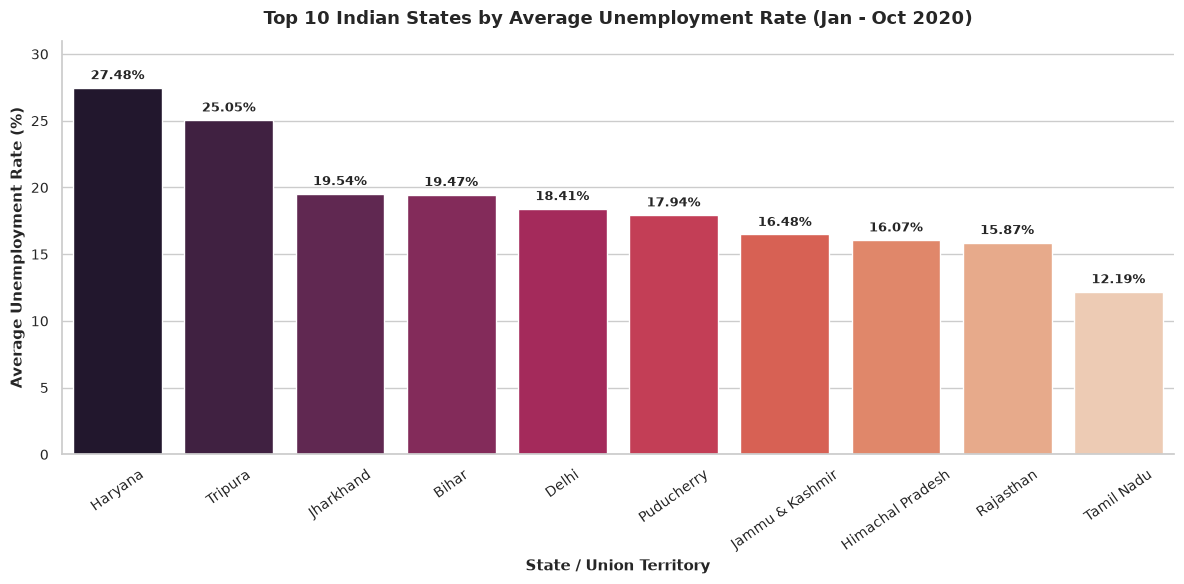

In [6]:
# Compute top 10 states by mean unemployment rate
top10_states = df.groupby('region')['unemployment_rate'].mean().sort_values(ascending=False).head(10).reset_index()

fig, ax = plt.subplots(figsize=(12, 6))
palette = sns.color_palette("rocket", n_colors=10)
bars = sns.barplot(data=top10_states, x='region', y='unemployment_rate', palette=palette, ax=ax)

# Value labels on top of bars
add_bar_labels(ax, fmt='{:.2f}%', padding=4)

apply_plot_styling(ax,
                   title="Top 10 Indian States by Average Unemployment Rate (Jan - Oct 2020)",
                   xlabel="State / Union Territory",
                   ylabel="Average Unemployment Rate (%)",
                   rotate_x=35)
ax.set_ylim(0, 31)
plt.tight_layout()
plt.show()

### Observations: Top 10 States Ranking
1. **Haryana** registered the highest overall average unemployment rate in India at **27.48%**, followed by **Tripura at 25.06%**, both experiencing chronic structural employment deficits throughout 2020.
2. Northern and eastern states including **Jharkhand (19.54%)**, **Bihar (19.47%)**, and the national capital **Delhi (18.41%)** occupied the third through fifth ranks.
3. Union territories and southern industrialized hubs, notably **Puducherry (17.94%)** and **Tamil Nadu (12.19%)**, entered the top 10 cohort primarily driven by unprecedented localized lockdown contractions rather than high baseline unemployment.

## 7. Correlation Analysis & Labour Force Dynamics
*Evaluate linear dependencies between unemployment rate, headcount employment, and labor participation rate.*

> [!NOTE]
> **Methodological Caveat on Employed Headcount**:
> The `employed` variable captures the **absolute count of individuals** in employment (headcount) rather than a normalized per-capita rate. Consequently, cross-state aggregate correlations are dominated by demographic scale differences across states (e.g., Uttar Pradesh and Maharashtra have far larger working headcounts than Goa or Sikkim).

--- Pearson Correlation Matrix ---


,unemployment_rate,employed,labour_participation_rate
unemployment_rate,1.0000,-0.2452,-0.0735
employed,-0.2452,1.0000,-0.0479
labour_participation_rate,-0.0735,-0.0479,1.0000


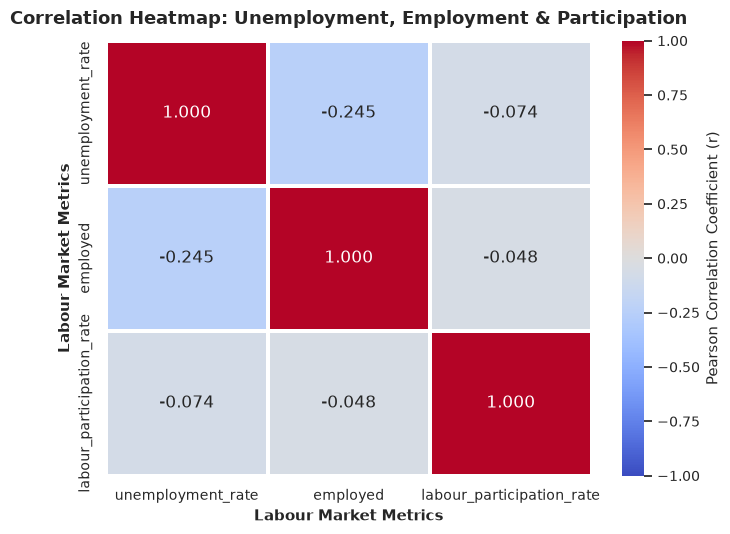

In [7]:
# Compute Pearson correlation matrix
metrics = ['unemployment_rate', 'employed', 'labour_participation_rate']
corr_matrix = df[metrics].corr()

print("--- Pearson Correlation Matrix ---")
display(corr_matrix.round(4))

fig, ax = plt.subplots(figsize=(7, 5.5))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(corr_matrix,
            annot=True,
            fmt='.3f',
            cmap='coolwarm',
            vmin=-1, vmax=1,
            cbar_kws={'label': 'Pearson Correlation Coefficient (r)'},
            linewidths=1.5,
            linecolor='white',
            ax=ax)

apply_plot_styling(ax,
                   title="Correlation Heatmap: Unemployment, Employment & Participation",
                   xlabel="Labour Market Metrics",
                   ylabel="Labour Market Metrics")
plt.tight_layout()
plt.show()

### Observations: Correlation Analysis
1. A modest negative correlation of **r = -0.245** exists between `unemployment_rate` and `employed`, capturing the contraction in total engaged workers during acute surge periods of unemployment.
2. The correlation between `labour_participation_rate` and `unemployment_rate` is weakly negative (**r = -0.074**), indicating that headline participation percentages remained relatively sticky even as active job seekers struggled to secure roles.
3. Similarly, `labour_participation_rate` and absolute `employed` headcount exhibit negligible correlation (**r = -0.048**), largely because headcount is governed by absolute state population scale rather than labor force attachment rates.

## 8. Pre- vs. Post-COVID-19 Impact Assessment
*Segment observations at March 25, 2020, compare aggregate national shifts, isolate the top 5 most disrupted states, and visualize post-shock percentage changes.*

--- National Labour Market Metrics: Pre vs Post COVID-19 Split ---


,Post-COVID,Pre-COVID,Absolute Change,% Relative Change
unemployment_rate,12.96,9.23,3.73,40.43
employed,13574977.29,15562732.90,-1987755.62,-12.77
labour_participation_rate,41.02,44.40,-3.38,-7.61



--- Top 5 Most Impacted States (by Absolute Unemployment Increase) ---


,Pre-COVID Mean (%),Post-COVID Mean (%),Absolute Change (pp),% Relative Change,Pre Employed,Post Employed,Employed % Change
region,,,,,,,
Puducherry,1.17,22.14,20.96,1791.88,475955.5,337589.75,-29.07
Tamil Nadu,1.83,14.78,12.95,707.45,27226115.0,20678343.88,-24.05
Bihar,10.45,21.73,11.28,107.91,26339663.0,22923619.25,-12.97
Jharkhand,11.23,21.62,10.39,92.49,10311727.0,8385371.25,-18.68
Goa,5.85,13.75,7.90,134.98,447409.0,441116.25,-1.41


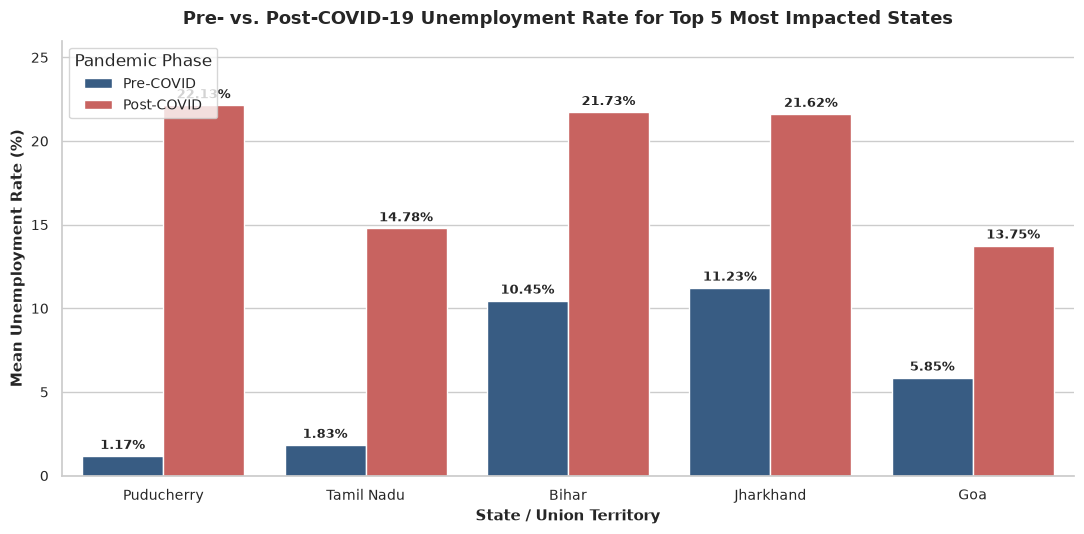

In [8]:
# Segment observations into Pre-COVID (prior to 25 Mar 2020) and Post-COVID
df['period'] = np.where(df['date'] < '2020-03-25', 'Pre-COVID', 'Post-COVID')

# 1. National overall comparison
overall_summary = df.groupby('period')[['unemployment_rate', 'employed', 'labour_participation_rate']].mean().T
overall_summary['Absolute Change'] = overall_summary['Post-COVID'] - overall_summary['Pre-COVID']
overall_summary['% Relative Change'] = (overall_summary['Absolute Change'] / overall_summary['Pre-COVID']) * 100
overall_summary.columns.name = None

print("--- National Labour Market Metrics: Pre vs Post COVID-19 Split ---")
display(overall_summary.round(2))

# 2. State-level comparison
state_pivot = df.pivot_table(
    index='region',
    columns='period',
    values=['unemployment_rate', 'employed', 'labour_participation_rate'],
    aggfunc='mean'
)

# Identify Top 5 most impacted states by absolute increase in unemployment rate
state_pivot['abs_u_change'] = state_pivot[('unemployment_rate', 'Post-COVID')] - state_pivot[('unemployment_rate', 'Pre-COVID')]
state_pivot['pct_u_change'] = (state_pivot['abs_u_change'] / state_pivot[('unemployment_rate', 'Pre-COVID')]) * 100
top5_affected = state_pivot.sort_values(by='abs_u_change', ascending=False).head(5)

# Build a clean comparative table for the top 5 states
top5_table = pd.DataFrame({
    'Pre-COVID Mean (%)': top5_affected[('unemployment_rate', 'Pre-COVID')],
    'Post-COVID Mean (%)': top5_affected[('unemployment_rate', 'Post-COVID')],
    'Absolute Change (pp)': top5_affected['abs_u_change'],
    '% Relative Change': top5_affected['pct_u_change'],
    'Pre Employed': top5_affected[('employed', 'Pre-COVID')],
    'Post Employed': top5_affected[('employed', 'Post-COVID')],
    'Employed % Change': ((top5_affected[('employed', 'Post-COVID')] - top5_affected[('employed', 'Pre-COVID')]) / top5_affected[('employed', 'Pre-COVID')]) * 100
})

print("\n--- Top 5 Most Impacted States (by Absolute Unemployment Increase) ---")
display(top5_table.round(2))

# 3. Grouped Bar Chart: Pre vs Post COVID Unemployment Rate for Top 5 Affected States
top5_plot_df = top5_table[['Pre-COVID Mean (%)', 'Post-COVID Mean (%)']].reset_index()
top5_melted = top5_plot_df.melt(id_vars='region', var_name='Period', value_name='Unemployment Rate')
top5_melted['Period'] = top5_melted['Period'].str.replace(' Mean (%)', '')

fig, ax = plt.subplots(figsize=(11, 5.5))
palette_comp = {'Pre-COVID': '#2b5c8f', 'Post-COVID': '#d9534f'}
bars = sns.barplot(data=top5_melted, x='region', y='Unemployment Rate', hue='Period', palette=palette_comp, ax=ax)

add_bar_labels(ax, fmt='{:.2f}%', padding=3)

apply_plot_styling(ax,
                   title="Pre- vs. Post-COVID-19 Unemployment Rate for Top 5 Most Impacted States",
                   xlabel="State / Union Territory",
                   ylabel="Mean Unemployment Rate (%)")
ax.set_ylim(0, 26)
ax.legend(title="Pandemic Phase", loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

### Observations: Pre vs. Post COVID Impact
1. Nationally, the average unemployment rate rose from **9.23% pre-COVID** to **12.96% post-COVID**, representing an absolute increase of **+3.73 percentage points** and a **+40.43% relative surge**.
2. Concurrently, mean employed headcount shrank from **15.56 million to 13.57 million** per state (a **-12.77% contraction**, shedding ~1.99 million jobs on average), while labor force participation slipped from **44.40% to 41.02% (-7.61%)**.
3. **Puducherry** suffered the highest relative shock, with unemployment surging from a **1.17% baseline to 22.14%** (+20.97 percentage points; **+1,791.88% relative increase**).
4. **Tamil Nadu** followed with an increase from **1.83% to 14.78%** (+12.95 pp; **+707.45% relative increase**), while **Bihar** and **Jharkhand** experienced post-lockdown rates above **21.6%**, up from pre-lockdown levels of 10.45% and 11.23% respectively.

## 9. Conclusion & Limitations

### Key Findings
1. **Unprecedented Lockdown Shock**: The national monthly unemployment rate spiked from a pre-lockdown average of **9.23%** (Jan-Feb 2020) to an all-time peak of **23.24% in May 2020**, with April and May absorbing the full brunt of nationwide commercial cessation.
2. **Sharp Disparities in State Vulnerability**: Coastal and industrialized regions like **Puducherry (+1,791.88%)** and **Tamil Nadu (+707.45%)** experienced immediate catastrophic disruptions despite near-zero pre-pandemic baselines, while **Haryana (27.48%)** and **Tripura (25.06%)** suffered from high chronic structural unemployment throughout.
3. **V-Shaped Labor Recovery**: Economic easing initiated during the Unlock phases triggered a rapid rebound; national unemployment contracted from **23.24% in May** to **10.91% in June**, reaching **8.03% by October 2020** (lower than the pre-lockdown benchmark).
4. **Dual Contraction in Participation and Employment**: Beyond visible unemployment, total headcount employment contracted nationally by **-12.77%** and average labor participation fell by **-3.38 percentage points (-7.61%)**, reflecting temporary labor force discouragement and rural-urban migration shifts.

### Methodological Limitations
1. **Short Pre-COVID Baseline Window**: The dataset records only two pre-shock monthly observations (January and February 2020), which restricts longitudinal time-series modeling and precludes seasonal adjustment.
2. **State-Level Spatial Aggregation**: The metrics are aggregated at the broad state/UT level, obscuring substantial intra-state variances between metropolitan urban centers, rural agrarian belts, and informal sector workers.
3. **Correlation is Not Causation**: While the temporal alignment with the March 25, 2020 lockdown is distinct, concurrent external factors (such as regional lockdown extensions, supply chain bottlenecks, agricultural harvesting seasons, and reverse migration) also compounded these macro dynamics.